# 01b – Single-qubit gates and Bloch sphere

In [1]:
# Imports and helper to compare exact Statevector probs vs. 4096-shot Aer counts
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from qiskit_aer import AerSimulator

def inspect_gate(qc, shots=4096, seed=42):
    sv = Statevector(qc)
    exact = sv.probabilities_dict()

    qc_m = qc.copy()
    qc_m.measure_all()
    sim = AerSimulator(seed_simulator=seed)
    counts = sim.run(transpile(qc_m, sim), shots=shots).result().get_counts()

    print("statevector:", np.round(sv.data, 4))
    for s in sorted(set(exact) | set(counts)):
        print(f"  |{s}>  exact={exact.get(s, 0.0):.4f}  sampled={counts.get(s, 0)/shots:.4f} ({counts.get(s, 0)}/{shots})")
    return sv, counts

In [2]:
# Pauli X (|0> -> |1>) and Hadamard H (|0> -> |+>)
qc_x = QuantumCircuit(1)
qc_x.x(0)
print("X on |0>:")
_, counts_x = inspect_gate(qc_x)
assert counts_x.get("1", 0) == 4096

qc_h = QuantumCircuit(1)
qc_h.h(0)
print("\nH on |0>:")
_, counts_h = inspect_gate(qc_h)
assert abs(counts_h.get("0", 0) - 2048) < 150

X on |0>:
statevector: [0.+0.j 1.+0.j]
  |1>  exact=1.0000  sampled=1.0000 (4096/4096)

H on |0>:
statevector: [0.7071+0.j 0.7071+0.j]
  |0>  exact=0.5000  sampled=0.4937 (2022/4096)
  |1>  exact=0.5000  sampled=0.5063 (2074/4096)


In [3]:
# Phase vs bit flip: Z alone doesn't change |0> or |+> probabilities in Z-basis,
# while H -> Z -> H turns the relative phase into a deterministic flip to |1>.
for label, gates in [("Z on |0>", ["z"]), ("H -> Z (|->)", ["h", "z"]), ("H -> Z -> H (= X)", ["h", "z", "h"])]:
    qc = QuantumCircuit(1)
    for g in gates:
        getattr(qc, g)(0)
    print(f"\n{label}:")
    _, c = inspect_gate(qc)
    if label == "Z on |0>":
        assert c.get("0", 0) == 4096
    elif label.startswith("H -> Z -> H"):
        assert c.get("1", 0) == 4096


Z on |0>:
statevector: [1.+0.j 0.+0.j]
  |0>  exact=1.0000  sampled=1.0000 (4096/4096)

H -> Z (|->):
statevector: [ 0.7071+0.j -0.7071+0.j]
  |0>  exact=0.5000  sampled=0.4937 (2022/4096)
  |1>  exact=0.5000  sampled=0.5063 (2074/4096)

H -> Z -> H (= X):


statevector: [0.+0.j 1.+0.j]
  |1>  exact=1.0000  sampled=1.0000 (4096/4096)


In [4]:
# Phase gates S (pi/2) and T (pi/4) after H: same Z-basis probs, different equatorial phase
qc_s = QuantumCircuit(1)
qc_s.h(0); qc_s.s(0)
print("H -> S (|+i>):")
sv_s, _ = inspect_gate(qc_s)

qc_t = QuantumCircuit(1)
qc_t.h(0); qc_t.t(0)
print("\nH -> T (pi/4 phase):")
sv_t, _ = inspect_gate(qc_t)

assert np.isclose(sv_s.data[1], 1j / np.sqrt(2))
assert np.isclose(sv_t.data[1], np.exp(1j * np.pi / 4) / np.sqrt(2))

H -> S (|+i>):
statevector: [0.7071+0.j     0.    +0.7071j]
  |0>  exact=0.5000  sampled=0.4937 (2022/4096)
  |1>  exact=0.5000  sampled=0.5063 (2074/4096)

H -> T (pi/4 phase):


statevector: [0.7071+0.j  0.5   +0.5j]
  |0>  exact=0.5000  sampled=0.4937 (2022/4096)
  |1>  exact=0.5000  sampled=0.5063 (2074/4096)


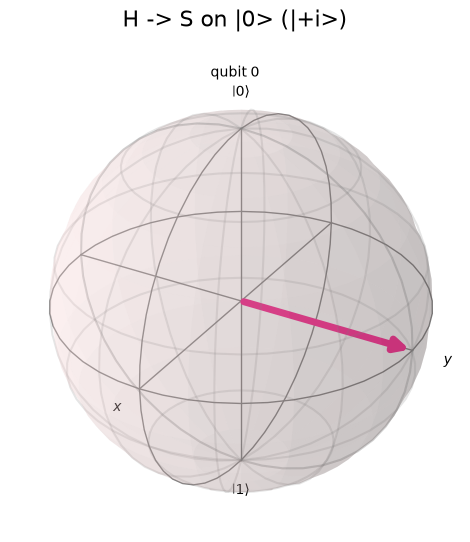

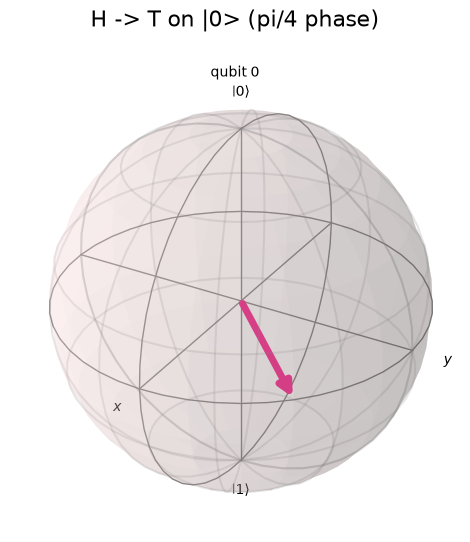

In [5]:
# Plot S|+> and T|+> on the Bloch sphere
from IPython.display import display
display(plot_bloch_multivector(sv_s, title="H -> S on |0> (|+i>)"))
display(plot_bloch_multivector(sv_t, title="H -> T on |0> (pi/4 phase)"))

## Continuous rotations and QAOA gates
In QAOA, problem cost terms compile to $R_Z$ phase rotations and the mixer layer uses parallel $R_X(2\beta)$ rotations across qubits.

In [6]:
# Continuous rotations Ry(pi/3), H -> Rz(pi/3), and Rx(pi/3)
qc_ry = QuantumCircuit(1)
qc_ry.ry(np.pi / 3, 0)
print("Ry(pi/3) on |0>:")
sv_ry, counts_ry = inspect_gate(qc_ry)
assert np.isclose(sv_ry.probabilities_dict()["0"], 0.75)
assert np.isclose(sv_ry.probabilities_dict()["1"], 0.25)

qc_rz = QuantumCircuit(1)
qc_rz.h(0); qc_rz.rz(np.pi / 3, 0)
print("\nH -> Rz(pi/3) on |0>:")
sv_rz, _ = inspect_gate(qc_rz)
assert np.isclose(sv_rz.probabilities_dict()["0"], 0.5)

qc_rx = QuantumCircuit(1)
qc_rx.rx(np.pi / 3, 0)
print("\nRx(pi/3) on |0>:")
sv_rx, _ = inspect_gate(qc_rx)
assert np.isclose(sv_rx.probabilities_dict()["0"], 0.75)
assert np.isclose(sv_rx.probabilities_dict()["1"], 0.25)

Ry(pi/3) on |0>:
statevector: [0.866+0.j 0.5  +0.j]
  |0>  exact=0.7500  sampled=0.7527 (3083/4096)
  |1>  exact=0.2500  sampled=0.2473 (1013/4096)

H -> Rz(pi/3) on |0>:
statevector: [0.6124-0.3536j 0.6124+0.3536j]
  |0>  exact=0.5000  sampled=0.4937 (2022/4096)
  |1>  exact=0.5000  sampled=0.5063 (2074/4096)

Rx(pi/3) on |0>:
statevector: [0.866+0.j  0.   -0.5j]
  |0>  exact=0.7500  sampled=0.7527 (3083/4096)
  |1>  exact=0.2500  sampled=0.2473 (1013/4096)
